# Dataset preparation



## 1. 📥​ Imports

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "tcibench" / "preparation" / "metadata.json").is_file()),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the tcibench project.")

sys.path.insert(0, str(PROJECT_ROOT / "src"))

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from tcibench.preparation import Dataset, load_dataset, load_metadata, plot_feature_distributions

In [3]:
RAW_ROOT = PROJECT_ROOT / "dataa" / "raw"

DATASET_PATHS = {
    "diabetes": RAW_ROOT / "diabetes.csv",
    "sick": RAW_ROOT / "sick.arff",
}

## 2. ⚙️​​ Utils

In [20]:
def inspect_dataset(dataset_id: str):
    """Show metadata, cleaning, split, class balance, and feature distributions."""
    if dataset_id not in DATASET_PATHS:
        raise ValueError(f"Choose one of: {', '.join(DATASET_PATHS)}")

    metadata = load_metadata(dataset_id)
    raw = load_dataset(DATASET_PATHS[dataset_id])
    dataset = Dataset(raw, metadata)
    cleaned, cleaning_stats = dataset.preprocessing.clean(raw)
    folds = dataset.preprocessing.split(cleaned)
    train, test, split_audit = folds[0]

    print(f"{metadata.display_name} | target: {metadata.target_column}")
    display(pd.DataFrame(metadata.columns).T)
    print(f"Raw data: {raw.shape[0]} rows, {raw.shape[1]} columns")
    display(raw.head())

    print("Cleaning")
    display(pd.Series(cleaning_stats, name="value").to_frame())
    display(cleaned.head())

    print("Train/test split")
    display(pd.Series(split_audit, name="value").to_frame())
    target = metadata.target_column
    display(pd.DataFrame({
        "train_count": train[target].value_counts(),
        "train_proportion": train[target].value_counts(normalize=True),
        "test_count": test[target].value_counts(),
        "test_proportion": test[target].value_counts(normalize=True),
    }).fillna(0).sort_index())

    figure = plot_feature_distributions(cleaned, train, test, metadata)
    plt.show()
    plt.close(figure)
    return train, test

## 3. 🔎 Inspect a dataset

Thyroid Sick | target: Class


,type,description
age,numeric,Patient age.
sex,categorical,Recorded sex of the patient.
on_thyroxine,categorical,Indicator of whether the patient is taking thy...
query_on_thyroxine,categorical,Indicator of a query or investigation related ...
on_antithyroid_medication,categorical,Indicator of whether the patient is taking ant...
sick,categorical,Indicator of whether the patient is recorded a...
pregnant,categorical,Indicator of whether the patient is recorded a...
thyroid_surgery,categorical,Indicator of whether the patient has undergone...
I131_treatment,categorical,Indicator of whether the patient is recorded a...
query_hypothyroid,categorical,Indicator of a query or suspicion related to h...


Raw data: 3772 rows, 30 columns


,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,Class
0,41.0,F,f,f,f,f,f,f,f,f,...,t,125.0,t,1.14,t,109.0,f,NaN,SVHC,negative
1,23.0,F,f,f,f,f,f,f,f,f,...,t,102.0,f,NaN,f,NaN,f,NaN,other,negative
2,46.0,M,f,f,f,f,f,f,f,f,...,t,109.0,t,0.91,t,120.0,f,NaN,other,negative
3,70.0,F,t,f,f,f,f,f,f,f,...,t,175.0,f,NaN,f,NaN,f,NaN,other,negative
4,70.0,F,f,f,f,f,f,f,f,f,...,t,61.0,t,0.87,t,70.0,f,NaN,SVI,negative


Cleaning


,value
original_rows,3772
cleaned_rows,2642
dropped_columns,[TBG]
all_missing_columns,[TBG]
missing_values_before_cleaning,6064
missing_values_by_column_before_cleaning,"{'age': 1, 'sex': 150, 'TSH': 369, 'T3': 769, ..."
removed_missing_rows,1129
removed_duplicate_rows,1
numeric_decimals,4
target_counts_before_cleaning,"{'negative': 3541, 'sick': 231}"


,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,referral_source,Class
0,41.0,F,f,f,f,f,f,f,f,f,...,2.5,t,125.0,t,1.14,t,109.0,f,SVHC,negative
1,70.0,F,f,f,f,f,f,f,f,f,...,1.2,t,61.0,t,0.87,t,70.0,f,SVI,negative
2,80.0,F,f,f,f,f,f,f,f,f,...,0.6,t,80.0,t,0.70,t,115.0,f,SVI,sick
3,66.0,F,f,f,f,f,f,f,f,f,...,2.2,t,123.0,t,0.93,t,132.0,f,SVI,negative
4,68.0,M,f,f,f,f,f,f,f,f,...,1.6,t,83.0,t,0.89,t,93.0,f,SVI,negative


Train/test split


,value
fold,1
n_splits,5
split_seed,42
input_rows,2642
train_rows,2113
test_rows,529
train_target_counts,"{'negative': 1944, 'sick': 169}"
test_target_counts,"{'negative': 486, 'sick': 43}"
majority_class,negative
minority_class,sick


,train_count,train_proportion,test_count,test_proportion
Class,,,,
negative,1944,0.920019,486,0.918715
sick,169,0.079981,43,0.081285


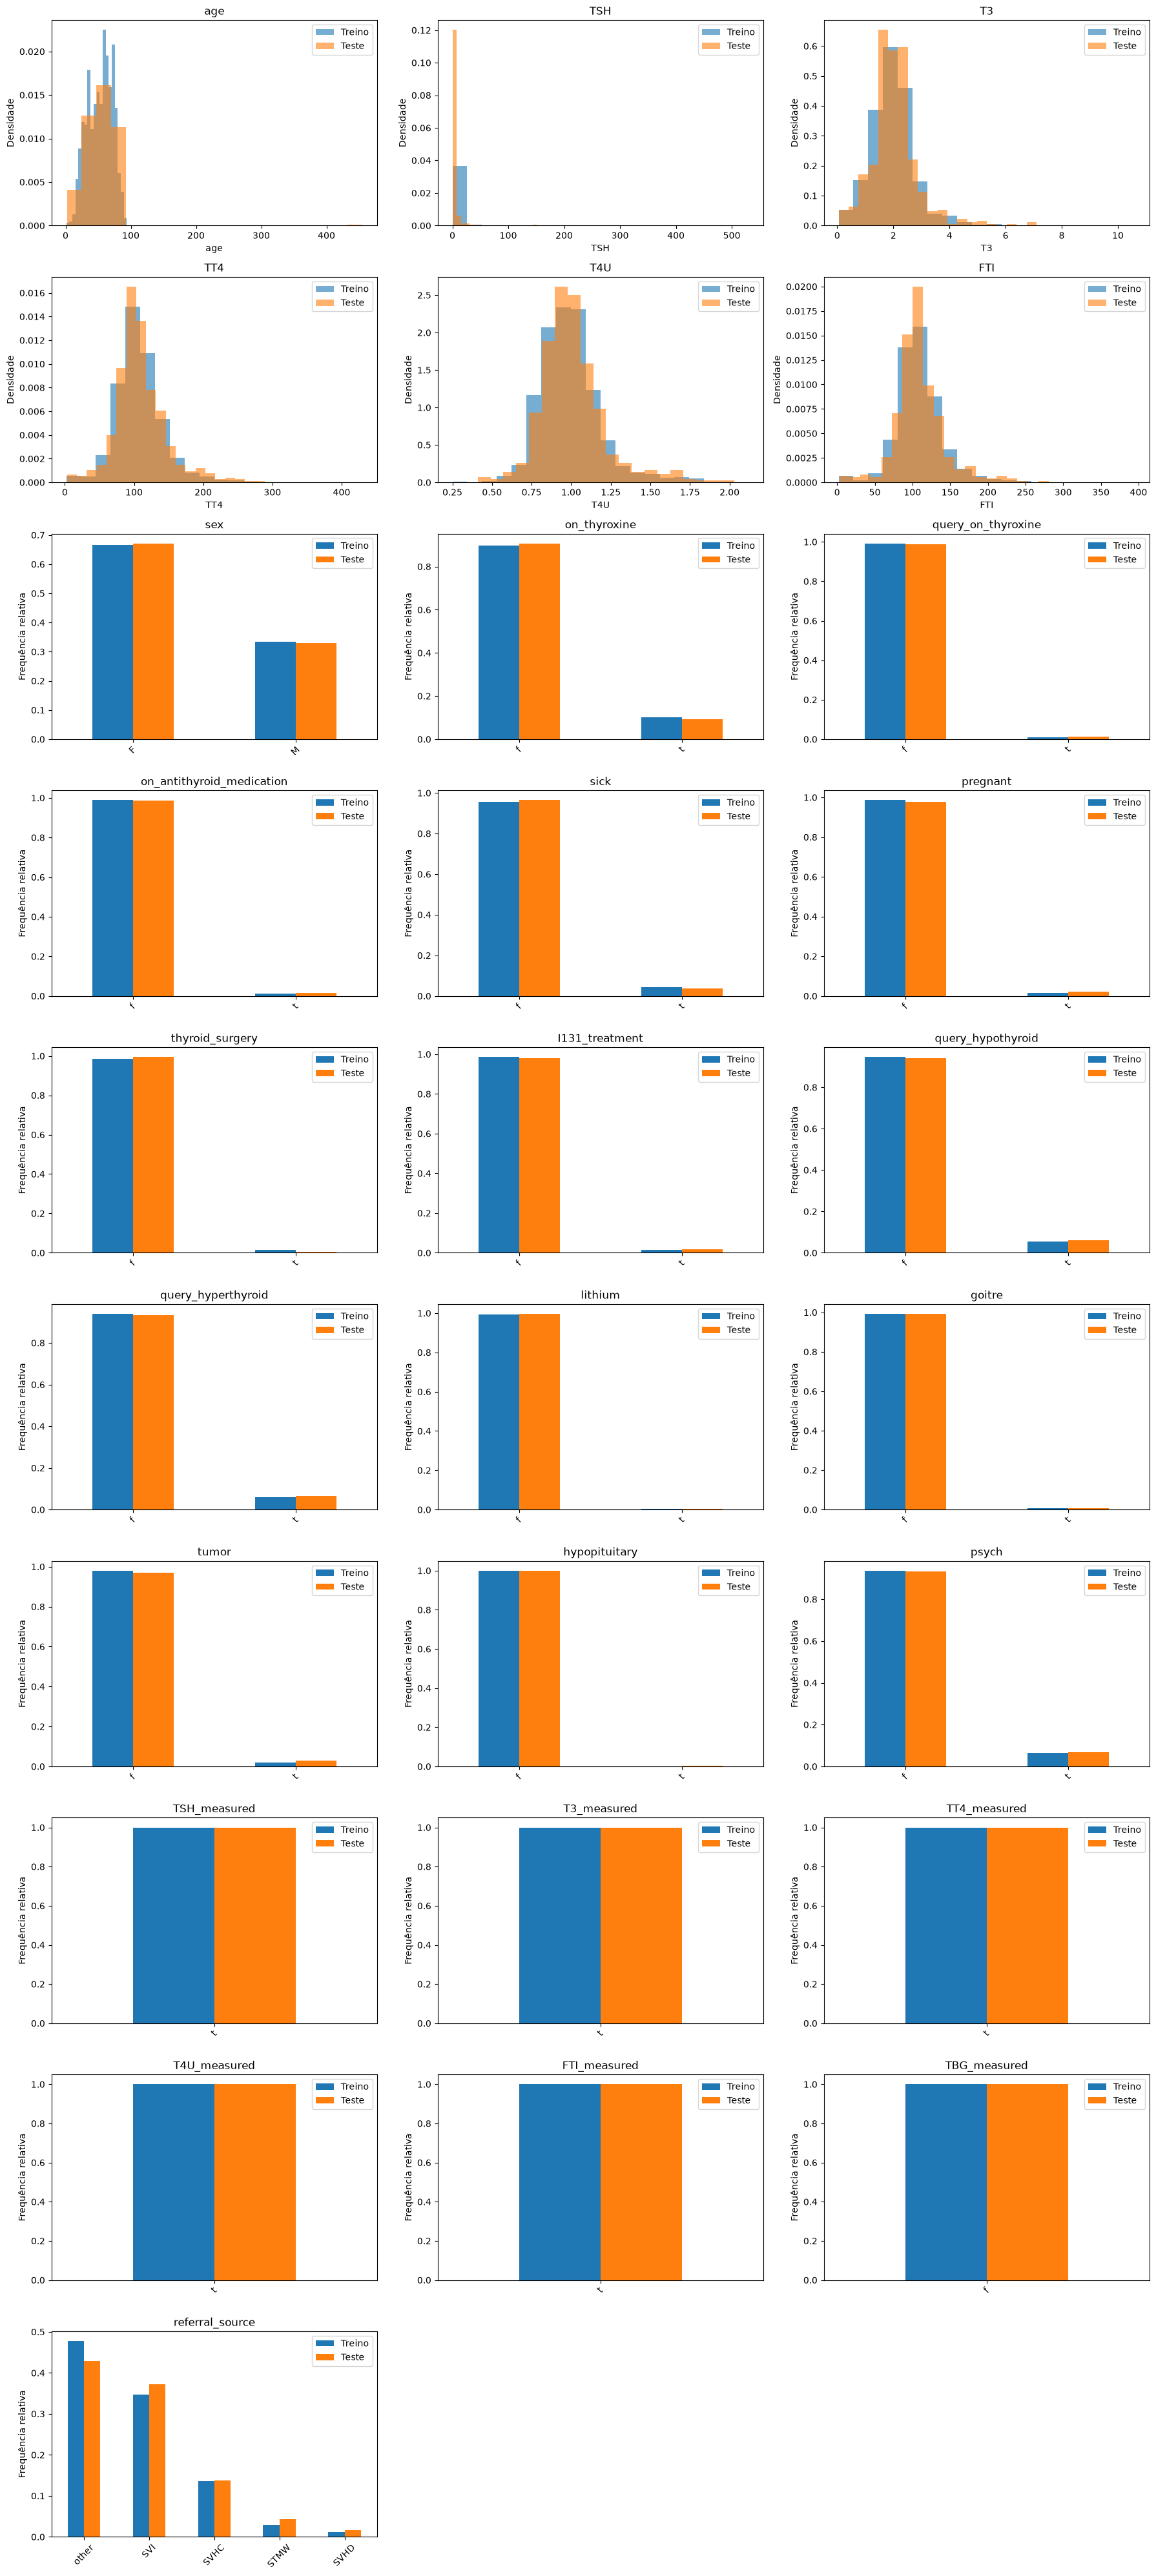

In [21]:
train, test = inspect_dataset("sick")